<center><h1>Huang_Hao_HW3</h1></center>
<br>
<br>

Name: Huang Hao
<br>
Github Username: Arvinhh7
<br>
USC ID: 8055359762

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
from pathlib import Path
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)
pd.set_option('display.precision', 5)
SEED = 552
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__)

Python: 3.14.6
NumPy: 2.4.6 | pandas: 3.0.3


Get the AReM Data Set

In [2]:
# Use the supplied local data; no download is needed.
ROOT = Path.cwd()
DATA_DIR = ROOT / 'AReM'
OUTPUT_DIR = ROOT / 'results'
OUTPUT_DIR.mkdir(exist_ok=True)
ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

def read_instance(path):
    # Comments contain metadata. Support both comma and whitespace separators,
    # and remove harmless trailing delimiters without changing sensor values.
    records = []
    for line in path.read_text().splitlines():
        if not line.strip() or line.lstrip().startswith('#'):
            continue
        fields = re.split(r'[,\s]+', line.strip().rstrip(','))
        if len(fields) != 7:
            raise ValueError(f'{path}: expected 7 fields, found {len(fields)}')
        records.append([float(value) for value in fields])
    frame = pd.DataFrame(records, columns=['time'] + SERIES)
    assert frame['time'].is_unique and frame['time'].is_monotonic_increasing
    assert np.isfinite(frame.to_numpy()).all()
    expected_times = np.arange(0, 120000, 250)
    missing_times = sorted(set(expected_times) - set(frame['time']))
    assert set(frame['time']).issubset(set(expected_times))
    # Keep every observed value. Do not fabricate an unobserved sensor row.
    return frame, missing_times

instances, audit = [], []
for activity in ACTIVITIES:
    paths = sorted((DATA_DIR / activity).glob('dataset*.csv'),
                   key=lambda p: int(re.search(r'dataset(\d+)', p.stem).group(1)))
    for path in paths:
        frame, missing = read_instance(path)
        number = int(re.search(r'dataset(\d+)', path.stem).group(1))
        instances.append({'activity': activity, 'dataset': number,
                          'file': f'{activity}/{path.name}', 'data': frame})
        audit.append({'activity': activity, 'dataset': number, 'rows': len(frame),
                      'missing_timestamps': str(missing),
                      'separator': 'comma' if ',' in path.read_text().splitlines()[5] else 'whitespace'})
audit = pd.DataFrame(audit)
assert len(instances) == 88
assert audit.groupby('activity').size().tolist() == [7, 6, 15, 15, 15, 15, 15]
assert (audit['rows'] >= 479).all()
display(audit.groupby('activity').agg(instances=('dataset', 'size'),
                                    min_rows=('rows', 'min'), max_rows=('rows', 'max')))
display(audit[(audit['rows'] != 480) | (audit['separator'] != 'comma')])
audit.to_csv(OUTPUT_DIR / 'data_audit.csv', index=False)

,instances,min_rows,max_rows
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,479,480
standing,15,480,480
walking,15,480,480


,activity,dataset,rows,missing_timestamps,separator
10,bending2,4,480,[],whitespace
50,sitting,8,479,[np.int64(13500)],comma


**Data cleaning.** The six sensor columns follow the names in the actual CSV headers (the last two names in the assignment contain typos). `bending2/dataset4.csv` uses whitespace rather than commas. `sitting/dataset8.csv` has 479 observations and one missing timestamp; the audit above identifies it. I retain its 479 observed rows rather than inventing a measurement. The seven statistics are valid for unequal sequence lengths, and no instance is discarded. Raw files are unchanged. All other files have 480 rows.

### (b) Test and Train Data

In [3]:
for item in instances:
    test_numbers = {1, 2} if item['activity'].startswith('bending') else {1, 2, 3}
    item['split'] = 'test' if item['dataset'] in test_numbers else 'train'
manifest = pd.DataFrame([{k: v for k, v in item.items() if k != 'data'} for item in instances])
manifest.insert(0, 'Instance', np.arange(1, 89))
display(pd.crosstab(manifest['activity'], manifest['split'], margins=True))
assert (manifest['split'].value_counts().to_dict() == {'train': 69, 'test': 19})
assert not set(manifest.loc[manifest.split == 'train', 'file']) & set(manifest.loc[manifest.split == 'test', 'file'])
manifest.to_csv(OUTPUT_DIR / 'split_manifest.csv', index=False)

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


### (c) Feature Extraction

#### i. Research

Common time-domain features include:

| Category | Examples | Information represented |
| --- | --- | --- |
| Level and location | Mean, median, minimum, maximum, quantiles | Typical signal level and extremes |
| Dispersion | Standard deviation, variance, range, interquartile range, median absolute deviation | Magnitude of fluctuations |
| Shape | Skewness, kurtosis | Asymmetry and tail behavior |
| Energy | Sum of squares, root mean square, mean absolute amplitude | Overall signal magnitude |
| Temporal behavior | Autocorrelation, linear trend, mean absolute successive change, threshold crossings, peak counts | Dependence, movement, and changes over time |

These examples are documented in the [tsfresh feature reference](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html). Fourier coefficients and spectral power are frequency-domain features, so they are outside the requested feature set. Summary statistics alone do not preserve temporal order.

#### ii. Extraction

In [4]:
STAT_NAMES = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']
feature_names = [f'{stat}{j}' for j in range(1, 7) for stat in STAT_NAMES]

def extract_features(frame):
    values = {}
    for j, column in enumerate(SERIES, start=1):
        s = frame[column]
        statistics = [s.min(), s.max(), s.mean(), s.median(),
                      s.std(ddof=1), s.quantile(0.25, interpolation='linear'),
                      s.quantile(0.75, interpolation='linear')]
        values.update({f'{name}{j}': value for name, value in zip(STAT_NAMES, statistics)})
    return values

X = pd.DataFrame([extract_features(item['data']) for item in instances], columns=feature_names)
assert X.shape == (88, 42) and np.isfinite(X.to_numpy()).all()
assert all((X[f'min{j}'] <= X[f'q1{j}']).all() and
           (X[f'q1{j}'] <= X[f'median{j}']).all() and
           (X[f'median{j}'] <= X[f'q3{j}']).all() and
           (X[f'q3{j}'] <= X[f'max{j}']).all() for j in range(1, 7))
features = pd.concat([manifest[['Instance', 'activity', 'dataset', 'split']], X], axis=1)
display(features)  # 88 instances; table is truncated only for screen readability.
features.to_csv(OUTPUT_DIR / 'features_all.csv', index=False)
features.loc[features.split == 'train'].to_csv(OUTPUT_DIR / 'features_train.csv', index=False)
features.loc[features.split == 'test'].to_csv(OUTPUT_DIR / 'features_test.csv', index=False)
print('Feature matrix:', X.shape, '| saved full tables to', OUTPUT_DIR)

,Instance,activity,dataset,split,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,median2,std2,q12,q32,min3,max3,mean3,median3,std3,q13,q33,min4,max4,mean4,median4,std4,q14,q34,min5,max5,mean5,median5,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,1,bending1,1,test,37.25,45.00,40.62479,40.50,1.47697,39.25,42.0000,0.0,1.30,0.35860,0.430,0.32260,0.00,0.5000,4.00,29.50,19.04094,19.250,4.46295,16.00,23.2500,0.0,7.23,0.83254,0.50,0.96566,0.0000,1.1200,27.25,38.25,34.31129,35.00,2.18845,33.0000,36.00,0.00,1.92,0.57058,0.43,0.58292,0.0000,1.3000
1,2,bending1,2,test,38.00,45.67,42.81281,42.50,1.43555,42.00,43.6700,0.0,1.22,0.37244,0.470,0.28916,0.00,0.5000,2.00,29.50,20.09698,21.000,3.89374,19.00,22.2500,0.0,5.76,0.87644,0.50,1.04726,0.0000,1.1450,27.67,38.50,33.02458,33.00,1.99525,32.0000,34.50,0.00,3.11,0.57108,0.43,0.60101,0.0000,1.3000
2,3,bending1,3,train,35.00,47.40,43.95450,44.33,1.55884,43.00,45.0000,0.0,1.70,0.42625,0.470,0.33869,0.00,0.5000,6.50,29.75,22.12235,23.000,3.03094,19.75,24.0000,0.0,4.44,0.49731,0.43,0.55066,0.0000,0.8300,29.00,38.50,35.58846,36.00,1.99960,35.3625,36.50,0.00,1.79,0.49329,0.43,0.51351,0.0000,0.9400
3,4,bending1,4,train,33.00,47.75,42.17981,43.50,3.67067,39.15,45.0000,0.0,3.00,0.69604,0.500,0.63086,0.00,1.1200,8.50,30.00,22.18362,23.000,3.81047,20.50,24.3725,0.0,5.15,0.98992,0.83,0.95373,0.4300,1.3000,20.00,38.67,33.49392,35.00,3.84945,30.4575,36.33,0.00,2.18,0.61352,0.50,0.52432,0.0000,1.0000
4,5,bending1,5,train,33.00,45.75,41.67806,41.75,2.24349,41.33,42.7500,0.0,2.83,0.53598,0.500,0.40547,0.43,0.7100,3.00,28.25,19.00656,19.125,4.08711,16.50,22.0625,0.0,6.42,0.84188,0.50,0.92880,0.4300,1.1200,23.67,37.50,29.85708,30.00,2.41103,28.4575,31.25,0.00,1.79,0.38329,0.43,0.38916,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,walking,11,train,19.50,45.33,33.58687,34.25,4.65094,30.25,37.0000,0.0,14.67,4.57656,4.260,2.46108,2.87,6.1050,7.33,23.25,15.31785,15.330,2.97044,13.25,17.2700,0.0,9.00,3.22723,3.10,1.64747,2.0500,4.2600,6.33,25.00,15.89215,16.00,3.28398,13.7300,18.25,0.00,8.32,3.25973,3.11,1.64024,2.0500,4.3225
84,85,walking,12,train,19.75,45.50,34.32275,35.25,4.75248,31.00,38.0000,0.0,13.47,4.45633,3.900,2.59928,2.49,5.9700,6.25,22.25,15.20977,15.250,2.71102,13.50,17.0000,0.0,9.00,3.27723,3.11,1.50005,2.1700,4.3900,6.25,23.25,15.55046,15.75,3.11986,13.5000,17.75,0.00,9.67,3.43256,3.20,1.73273,2.1575,4.5650
85,86,walking,13,train,19.50,46.00,34.54623,35.25,4.84229,31.25,37.8125,0.0,12.47,4.37196,4.135,2.36045,2.49,5.8000,7.00,22.67,15.18573,15.250,2.75760,13.25,17.0000,0.0,8.34,3.02869,2.86,1.66518,1.7900,4.1100,7.00,22.75,15.75954,15.75,2.82312,14.0000,17.75,0.00,10.00,3.33813,3.08,1.65674,2.1600,4.3350
86,87,walking,14,train,23.50,46.25,34.87323,35.25,4.53172,31.75,38.2500,0.0,14.82,4.38058,3.925,2.43544,2.50,5.9325,6.67,24.25,15.47119,15.500,2.81308,13.50,17.2500,0.0,9.90,3.20569,3.03,1.51935,2.0575,4.1900,5.50,23.50,15.87390,16.00,3.13108,13.7500,18.00,0.00,9.51,3.42465,3.27,1.69096,2.1700,4.5000


Feature matrix: (88, 42) | saved full tables to D:\dsci552\hw3\results


#### iii. Standard Deviation

,feature,sample_sd,ci_90_lower,ci_90_upper
0,min1,9.56998,8.27027,10.75838
1,max1,4.39436,3.32187,5.29486
2,mean1,5.33572,4.70793,5.88113
3,median1,5.44005,4.79378,5.99609
4,std1,1.77215,1.57133,1.95161
5,q11,6.15359,5.58210,6.64543
6,q31,5.13892,4.33194,5.84072
7,min2,0.00000,0.00000,0.00000
8,max2,5.06273,4.62504,5.40704
9,mean2,1.57416,1.39409,1.70688


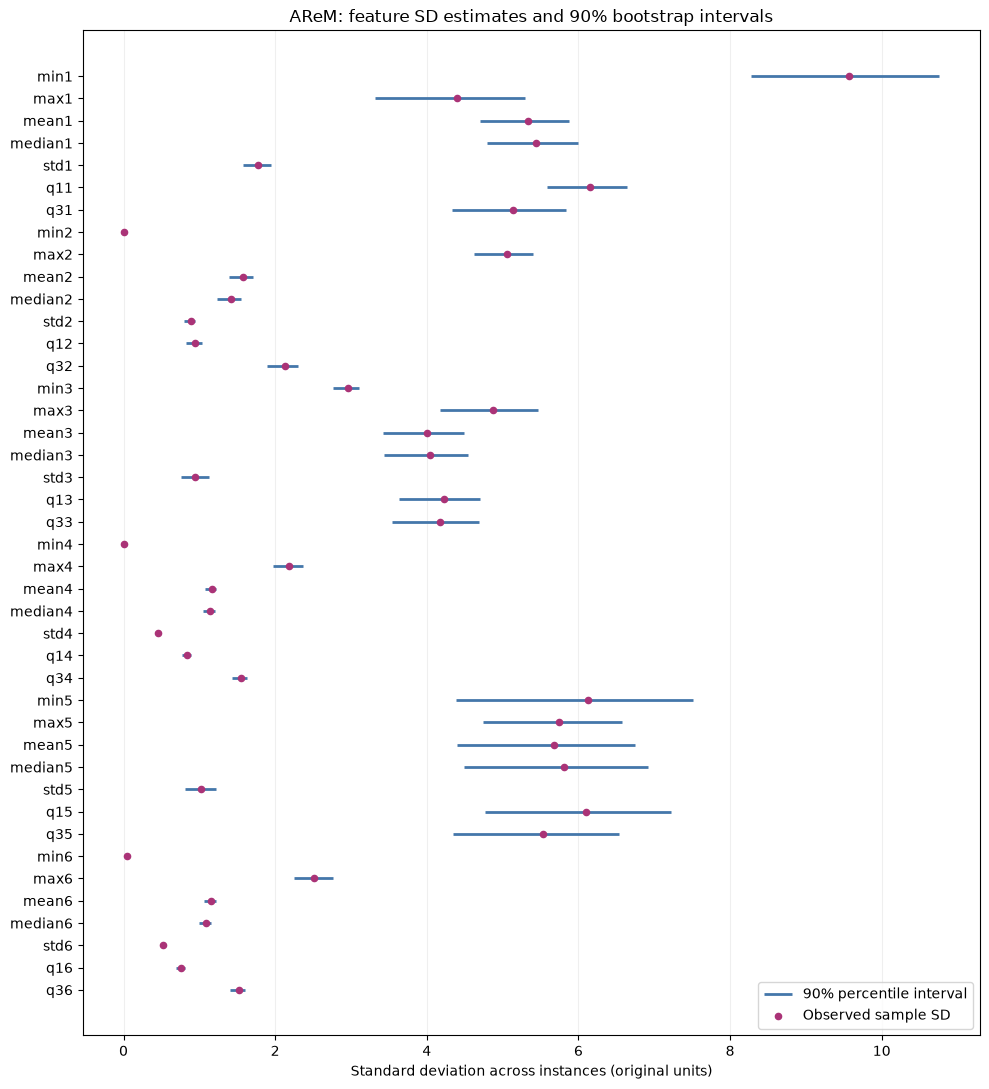

In [5]:
# Sample SD across the 88 instances, distinct from std1,...,std6 within an instance.
# Resample whole instance rows, preserving dependence among their 42 features.
N_BOOTSTRAP = 20000
BOOTSTRAP_BATCH = 250
rng = np.random.default_rng(SEED)
matrix = X.to_numpy()
n = len(matrix)
bootstrap_sd = np.empty((N_BOOTSTRAP, matrix.shape[1]))
for start in range(0, N_BOOTSTRAP, BOOTSTRAP_BATCH):
    stop = min(start + BOOTSTRAP_BATCH, N_BOOTSTRAP)
    sampled_rows = rng.integers(0, n, size=(stop - start, n))
    bootstrap_sd[start:stop] = matrix[sampled_rows].std(axis=1, ddof=1)
lower, upper = np.quantile(bootstrap_sd, [0.05, 0.95], axis=0)
sd_ci = pd.DataFrame({'feature': feature_names,
                      'sample_sd': matrix.std(axis=0, ddof=1),
                      'ci_90_lower': lower, 'ci_90_upper': upper})
assert len(sd_ci) == 42 and (sd_ci.ci_90_lower <= sd_ci.ci_90_upper).all()
display(sd_ci)
sd_ci.to_csv(OUTPUT_DIR / 'feature_sd_bootstrap_90ci.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 11))
positions = np.arange(len(sd_ci))
ax.hlines(positions, lower, upper, color='#4477AA', lw=2, label='90% percentile interval')
ax.scatter(sd_ci.sample_sd, positions, color='#AA3377', s=20, label='Observed sample SD', zorder=3)
ax.set_yticks(positions, feature_names)
ax.invert_yaxis()
ax.set_xlabel('Standard deviation across instances (original units)')
ax.set_title('AReM: feature SD estimates and 90% bootstrap intervals')
ax.grid(axis='x', alpha=0.2)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'bootstrap_sd_intervals.png', dpi=160)
plt.show()

**Method and interpretation.** Within each sequence and across instances, standard deviations use the sample convention `ddof=1`. Quartiles use linear interpolation. Features remain in their original units. For each feature, the table reports its SD over all 88 instances and the 5th and 95th percentiles of 20,000 bootstrap SD estimates, giving a pointwise 90% percentile interval. Each replicate samples 88 instances with replacement, not individual time points. This follows the descriptive request for all instances; test data are not used to choose features or fit a model. These intervals assume exchangeable instances from the observed activity mixture. Dependence among recordings and changes in class proportions limit their population interpretation. They are not simultaneous intervals, nor intervals for the mean, nor prediction intervals.

#### iv. Select Features

I select **mean, standard deviation, and median** as three feature types, applied to all six series (18 columns).

- **Mean** summarizes the typical RSS or variability level associated with an activity and sensor geometry.
- **Standard deviation** adds information about fluctuation intensity, which can help distinguish dynamic activities from relatively static postures.
- **Median** supplies a typical level that is less sensitive to occasional extreme sensor readings than the mean.

Mean and median can be correlated, but their difference can describe asymmetric recordings. Minima and maxima depend strongly on occasional extremes; quartiles are useful alternatives but overlap with the robust location information. This is a qualitative choice under the assignment's judgment criterion, not a claim that these features maximize classification accuracy. No test labels or fitted classifier are used to select them. A future predictive comparison should perform selection inside training cross-validation.

## 2. ISLR 3.7.4

### (a) Linear Train

I think cubic model has training RSS no greater than the linear model, even when the true relationship is linear. Setting $\beta_2=\beta_3=0$ makes every linear fit available within the cubic model. Least squares minimizes RSS over this larger model space, so $RSS_{cubic,train}\leq RSS_{linear,train}$. With noisy data, the extra terms usually reduce training RSS by fitting some noise; equality is possible.

### (b) Linear Test

When the true relationship is linear, we generally expect the linear model to have lower test RSS, for an independent test set drawn from the same population. I think both models can represent the true conditional mean, but estimating the unnecessary quadratic and cubic coefficients increases variance without removing systematic approximation bias. This is an expectation from the bias-variance tradeoff, not a guaranteed ordering on every realized test set.

### (c) Not Linear Train

The cubic model again has training RSS no greater than the linear model, regardless of the true nonlinear relationship. And the nesting argument still applies: its least-squares optimization includes all linear fits. It will generally be strictly lower when the extra polynomial terms explain variation, although equality remains possible.

### (d) Not Linear Testing

I think here is not enough information to determine which model has lower test RSS. Nonlinearity alone does not specify its shape, strength, or noise level. A substantial quadratic or cubic component may make the cubic model's bias reduction outweigh its extra variance; weak nonlinearity or high noise can favor the linear model. The true relationship could also have a shape that neither model captures well. Training RSS ordering therefore does not establish test RSS ordering.